# Overall model evaluation and final Kaggle submission

This notebook compares predictions from every modelling pipeline on one common
chronological validation window. It is intentionally separate from model
training: each team member exports row-level predictions, and this notebook
audits, scores, ranks and visualises them.

**Comparison protocol**

- Fit period: January 2021–March 2024.
- Validation period: April 2024–March 2025 (35,158 valid rows).
- Primary selection metric: validation RMSE in SGD.
- Official Kaggle test: March 2025–July 2026 (50,000 rows; labels unavailable).
- Validation predictions must come from models that did not fit on validation
  labels. Final-refit predictions are used only after model selection.

The loader supports both team formats: the descriptive `ROW_ID,prediction`
files and compact Kaggle-style `Id,Predicted` files. Different filenames and
prediction-column names are declared explicitly below. A model is excluded
rather than silently compared if its validation IDs do not exactly match the
common validation set.


## 1. Configuration and model manifest

Normally no paths need editing on the original machine. If the folders are
moved or uploaded, add their parent folders to `PREDICTION_BUNDLE_OVERRIDES`.
Each bundle must contain `train/`, `val/` and/or `test/` subfolders.

Model selection always uses predictions produced without fitting on the
validation window. Final-refit files (usually named `retrained_...`) are used
only for official-test prediction checks after selection. In particular, the
Lasso + Random Forest bundle keeps `train/two_stage_lasso_rf.csv` and
`val/two_stage_lasso_rf.csv` for fair evaluation, while
`test/retrained_two_stage_lasso_rf.csv` represents its train + validation
refit for the unseen Kaggle rows.

All listed models have now been confirmed by their authors as final-refit
outputs. The notebook still validates file shape, identifiers and finite
predictions before any file can be used for submission.


In [1]:
from pathlib import Path
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid")

PREDICTION_BUNDLE_OVERRIDES = []
LABEL_DATA_ROOT_OVERRIDE = None

PRIMARY_METRIC = "RMSE"
CONFIRMED_FINAL_TEST_MODELS = {
    "catboost_raw",
    "static_temporal_ffn",
    "temporal_ffn",
    "two_stage_ffn_rf",
    "two_stage_lasso_rf",
    "time_series_plus_residual",
    "gaussian_process_xgboost",
}
FINAL_TEST_FILE_OVERRIDES = {}

MODEL_SPECS = {
    "catboost_raw": {
        "display": "CatBoost raw",
        "train": ["train/catboost_raw.csv"],
        "val": ["val/catboost_raw.csv"],
        "final_test": ["test/retrained_catboost_raw.csv", "test/final_catboost_raw.csv"],
    },
    "static_temporal_ffn": {
        "display": "Static + temporal FFN",
        "train": ["train/static_temporal_ffn.csv"],
        "val": ["val/static_temporal_ffn.csv"],
        "final_test": ["test/retrained_static_temporal_ffn.csv"],
    },
    "temporal_ffn": {
        "display": "Temporal-only FFN",
        "train": ["train/temporal_ffn.csv"],
        "val": ["val/temporal_ffn.csv"],
        "final_test": ["test/retrained_temporal_ffn.csv"],
    },
    "two_stage_ffn_rf": {
        "display": "Two-stage FFN + Random Forest",
        "train": ["train/two_stage_ffn_rf.csv"],
        "val": ["val/two_stage_ffn_rf.csv"],
        "final_test": ["test/retrained_two_stage_ffn_rf.csv"],
    },
    "two_stage_lasso_rf": {
        "display": "Two-stage Lasso + Random Forest",
        "train": ["train/two_stage_lasso_rf.csv"],
        "val": ["val/two_stage_lasso_rf.csv"],
        "final_test": ["test/retrained_two_stage_lasso_rf.csv"],
    },
    "time_series_plus_residual": {
        "display": "Two-stage Holt + XGBoost residual",
        "train": ["train/time_series_plus_residual_best_model_train_predictions.csv"],
        "val": ["val/time_series_plus_residual_best_model_validation_predictions.csv"],
        "final_test": ["test/submission_time_series_plus_residual_best_model.csv"],
    },
    "gaussian_process_xgboost": {
        "display": "Gaussian Process + XGBoost",
        "train": ["train/gaussian_process_best_model_train_predictions.csv"],
        "val": ["val/gaussian_process_best_model_validation_predictions.csv",
                "val/gaussian_process_best_model_train_predictions.csv"],
        "prediction_column": "gpr_xgb_stage2_prediction",
        "final_test": ["test/gaussian_process_best_model_predictions.csv"],
    },
}


import os, sys
from pathlib import Path
_here = Path(os.environ.get('RENT_PROJECT_ROOT') or Path.cwd()).resolve()
sys.path.insert(0, str(next(p for p in [_here, *_here.parents] if (p / 'data' / 'config.py').exists())))      # final_report: data/config.py holds every path
from data import config as cfg

PROJECT_ROOT = cfg.ROOT
OUTPUT_ROOT = cfg.OVERALL_OUTPUT_DIR
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Outputs:      {OUTPUT_ROOT}")


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\eliga\\AppData\\Local\\matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Project root: C:\Users\eliga\Downloads\Project_export
Outputs:      C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs


In [2]:
def looks_like_bundle(path: Path) -> bool:
    return path.is_dir() and any((path / split).is_dir() for split in ["train", "val", "test"])


def add_bundle(candidates, path):
    path = Path(path).expanduser().resolve()
    if looks_like_bundle(path) and path not in candidates:
        candidates.append(path)


def discover_prediction_bundles():
    bundles = []
    for override in PREDICTION_BUNDLE_OVERRIDES:
        add_bundle(bundles, override)

    env_value = os.environ.get("CS5228_PREDICTION_BUNDLES", "")
    for value in [item for item in env_value.split(os.pathsep) if item]:
        add_bundle(bundles, value)

    automatic = [
        # The dedicated Lasso bundle is listed first so its newly retrained
        # official-test predictions take precedence over older bundles.
        *cfg.PREDICTION_BUNDLE_SEARCH_DIRS,      # data/config.py
        Path.cwd() / "predictions",
    ]
    for candidate in automatic:
        add_bundle(bundles, candidate)
        if candidate.is_dir():
            for child in candidate.iterdir():
                add_bundle(bundles, child)

    if not bundles:
        raise FileNotFoundError(
            "No prediction bundles were found. Set PREDICTION_BUNDLE_OVERRIDES "
            "to folders containing train/val/test subfolders."
        )
    return bundles


def label_bundle_is_valid(path: Path) -> bool:
    return (path / "train.csv").is_file() and (path / "test.csv").is_file()


def resolve_label_data_root():
    candidates = []
    if LABEL_DATA_ROOT_OVERRIDE is not None:
        candidates.append(Path(LABEL_DATA_ROOT_OVERRIDE).expanduser())
    env_path = os.environ.get("CS5228_LABEL_DATA_ROOT")
    if env_path:
        candidates.append(Path(env_path).expanduser())
    candidates.extend(cfg.LABEL_DATA_SEARCH_DIRS)      # data/config.py
    for candidate in candidates:
        candidate = candidate.resolve()
        if label_bundle_is_valid(candidate):
            return candidate
    raise FileNotFoundError(
        "Could not find original_dataset/train.csv and test.csv. Set "
        "LABEL_DATA_ROOT_OVERRIDE."
    )


BUNDLE_ROOTS = discover_prediction_bundles()
LABEL_DATA_ROOT = resolve_label_data_root()

print("Prediction bundles:")
for root in BUNDLE_ROOTS:
    print(f"  - {root}")
print(f"Labels: {LABEL_DATA_ROOT}")


Prediction bundles:
  - C:\Users\eliga\Downloads\Telegram Desktop\lasso\lasso
  - C:\Users\eliga\Downloads\Telegram Desktop\predictions\predictions
  - C:\Users\eliga\Downloads\Telegram Desktop\predictions-MarkLim\predictions-MarkLim
  - C:\Users\eliga\Downloads\Telegram Desktop\predictions-CatBoost\predictions-CatBoost
Labels: C:\Users\eliga\Downloads\Telegram Desktop\final_report\final_report\data\original_dataset


## 2. Load labels and define the common chronological split

`ROW_ID` is the original zero-based row position. This preserves alignment
even if a preprocessing pipeline removed the one invalid labelled record.
The expected validation IDs are derived from the raw approval month, not from
any model's files.


In [3]:
TARGET = "MONTHLY_RENT"
FIT_END = pd.Timestamp("2024-03-01")
VALIDATION_START = pd.Timestamp("2024-04-01")
VALIDATION_END = pd.Timestamp("2025-03-01")
# ROW_ID 31739 is the single labelled record absent from the shared processed
# modelling dataset. Keep the original ROW_ID numbering, but exclude it from
# the canonical fit-row set used for coverage checks.
EXCLUDED_PROCESSED_ROW_IDS = {31739}

actuals = pd.read_csv(
    LABEL_DATA_ROOT / "train.csv",
    usecols=["RENT_APPROVAL_DATE", "FLAT_TYPE", "TOWN", TARGET],
)
actuals.insert(0, "ROW_ID", np.arange(len(actuals), dtype=int))
actuals["RENT_APPROVAL_DATE"] = pd.to_datetime(
    actuals["RENT_APPROVAL_DATE"], format="%Y-%m", errors="coerce"
)
actuals["FLAT_TYPE"] = actuals["FLAT_TYPE"].astype(str).str.replace("-", " ").str.lower()

valid_label = (
    actuals[TARGET].notna()
    & actuals["RENT_APPROVAL_DATE"].notna()
    & ~actuals["ROW_ID"].isin(EXCLUDED_PROCESSED_ROW_IDS)
)
expected_train = actuals.loc[valid_label & actuals["RENT_APPROVAL_DATE"].le(FIT_END)].copy()
expected_val = actuals.loc[
    valid_label
    & actuals["RENT_APPROVAL_DATE"].between(VALIDATION_START, VALIDATION_END)
].copy()

official_test = pd.read_csv(LABEL_DATA_ROOT / "test.csv", usecols=["RENT_APPROVAL_DATE"])
official_test.insert(0, "ROW_ID", np.arange(len(official_test), dtype=int))

print(f"Fit rows:        {len(expected_train):,} ({expected_train.RENT_APPROVAL_DATE.min():%Y-%m} to {expected_train.RENT_APPROVAL_DATE.max():%Y-%m})")
print(f"Validation rows: {len(expected_val):,} ({expected_val.RENT_APPROVAL_DATE.min():%Y-%m} to {expected_val.RENT_APPROVAL_DATE.max():%Y-%m})")
print(f"Test rows:       {len(official_test):,}")

assert len(expected_val) == 35_158, "Unexpected validation size; check source data."
assert len(official_test) == 50_000, "Unexpected official-test size."


Fit rows:        114,841 (2021-01 to 2024-03)
Validation rows: 35,158 (2024-04 to 2025-03)
Test rows:       50,000


## 3. Discover, standardise and audit every prediction file

Train coverage may be partial because some time-series methods deliberately
start after an initial history window. Such train metrics are labelled as
partial and should not be used to compare generalisation gaps. Validation is
stricter: every eligible model must predict exactly the same 35,158 rows.


In [4]:
ID_NAMES = {"row_id", "id"}
PREDICTION_NAMES = {"prediction", "predicted", "y_pred"}
ACTUAL_NAMES = {"actual_monthly_rent", "monthly_rent", "actual", "y_true"}


def locate_file(relative_candidates):
    for relative in relative_candidates:
        for root in BUNDLE_ROOTS:
            path = root / relative
            if path.is_file():
                return path
    return None


def identify_column(columns, allowed, description):
    matches = [column for column in columns if column.lower() in allowed]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one {description} column from {sorted(allowed)}; found {matches}."
        )
    return matches[0]


def load_predictions(path, prediction_column=None):
    frame = pd.read_csv(path)
    id_column = identify_column(frame.columns, ID_NAMES, "identifier")
    if prediction_column is None:
        prediction_column = identify_column(frame.columns, PREDICTION_NAMES, "prediction")
    elif prediction_column not in frame.columns:
        # Some pipelines use a model-specific column for validation but the
        # standard Kaggle `Predicted` name for their final submission file.
        standard_matches = [
            column for column in frame.columns
            if column.lower() in PREDICTION_NAMES
        ]
        if len(standard_matches) == 1:
            prediction_column = standard_matches[0]
        else:
            raise ValueError(
                f"Missing configured prediction column {prediction_column!r} "
                "and no unique standard prediction column was found."
            )

    actual_matches = [column for column in frame.columns if column.lower() in ACTUAL_NAMES]
    keep = [id_column, prediction_column] + actual_matches[:1]
    result = frame[keep].rename(columns={id_column: "ROW_ID", prediction_column: "PREDICTION"})
    if actual_matches:
        result = result.rename(columns={actual_matches[0]: "EMBEDDED_ACTUAL"})
    result["ROW_ID"] = pd.to_numeric(result["ROW_ID"], errors="raise").astype(int)
    result["PREDICTION"] = pd.to_numeric(result["PREDICTION"], errors="raise")
    if result["ROW_ID"].duplicated().any():
        raise ValueError("ROW_ID contains duplicates.")
    if not np.isfinite(result["PREDICTION"]).all():
        raise ValueError("Predictions contain missing or non-finite values.")
    return result.sort_values("ROW_ID").reset_index(drop=True)


def regression_metrics(actual, prediction):
    residual = prediction - actual
    return {
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": mean_squared_error(actual, prediction) ** 0.5,
        "R2": r2_score(actual, prediction),
        "BIAS": residual.mean(),
    }


expected_ids = {
    "train": np.sort(expected_train["ROW_ID"].to_numpy()),
    "validation": np.sort(expected_val["ROW_ID"].to_numpy()),
}


def score_row_file(model, display_name, split, path, prediction_column=None):
    prediction = load_predictions(path, prediction_column)
    label_source = expected_train if split == "train" else expected_val
    scored = prediction.merge(actuals, on="ROW_ID", how="left", validate="one_to_one")
    if scored[TARGET].isna().any():
        raise ValueError("Some ROW_ID values do not match labelled rows.")

    if "EMBEDDED_ACTUAL" in scored:
        embedded = pd.to_numeric(scored["EMBEDDED_ACTUAL"], errors="coerce")
        max_difference = (embedded - scored[TARGET]).abs().max()
        if pd.isna(max_difference) or max_difference > 1e-6:
            raise ValueError(f"Embedded actual values disagree with source labels (max difference {max_difference}).")

    supplied_ids = prediction["ROW_ID"].to_numpy()
    allowed_ids = set(label_source["ROW_ID"])
    outside = [row_id for row_id in supplied_ids if row_id not in allowed_ids]
    if outside:
        raise ValueError(f"Contains {len(outside):,} ROW_ID values outside the common {split} period.")

    exact_window = np.array_equal(supplied_ids, expected_ids[split])
    if split == "validation" and not exact_window:
        missing = len(set(expected_ids[split]) - set(supplied_ids))
        raise ValueError(
            f"Validation ROW_ID set is incomplete or different: {len(supplied_ids):,} supplied, "
            f"{missing:,} expected IDs missing."
        )

    coverage = len(supplied_ids) / len(expected_ids[split])
    row = {
        "model": model,
        "display_name": display_name,
        "split": split,
        "rows": len(scored),
        "coverage": coverage,
        "full_common_window": exact_window,
        "date_start": scored["RENT_APPROVAL_DATE"].min(),
        "date_end": scored["RENT_APPROVAL_DATE"].max(),
        "metric_source": "row-level predictions",
        **regression_metrics(scored[TARGET], scored["PREDICTION"]),
    }
    return scored, row


In [5]:
metric_rows = []
audit_rows = []
prediction_cache = {"train": {}, "validation": {}}

for model, spec in MODEL_SPECS.items():
    display_name = spec["display"]
    model_audit = {
        "model": model,
        "display_name": display_name,
        "train_file": None,
        "validation_file": None,
        "train_status": "not supplied",
        "validation_status": "not supplied",
        "eligible_for_ranking": False,
    }
    for split, key in [("train", "train"), ("validation", "val")]:
        path = locate_file(spec.get(key, []))
        if path is None:
            continue
        model_audit[f"{split}_file"] = str(path)
        try:
            scored, metric_row = score_row_file(
                model,
                display_name,
                split,
                path,
                spec.get("prediction_column"),
            )
            prediction_cache[split][model] = scored
            metric_rows.append(metric_row)
            coverage = metric_row["coverage"]
            qualifier = "full common window" if metric_row["full_common_window"] else f"partial ({coverage:.1%})"
            model_audit[f"{split}_status"] = f"valid; {qualifier}"
            if split == "validation":
                model_audit["eligible_for_ranking"] = True
        except Exception as error:
            model_audit[f"{split}_status"] = f"INVALID: {error}"
    audit_rows.append(model_audit)

audit = pd.DataFrame(audit_rows).set_index("model")
display(audit[["display_name", "train_status", "validation_status", "eligible_for_ranking"]])


,display_name,train_status,validation_status,eligible_for_ranking
model,,,,
catboost_raw,CatBoost raw,valid; full common window,valid; full common window,True
static_temporal_ffn,Static + temporal FFN,valid; full common window,valid; full common window,True
temporal_ffn,Temporal-only FFN,valid; full common window,valid; full common window,True
two_stage_ffn_rf,Two-stage FFN + Random Forest,valid; full common window,valid; full common window,True
two_stage_lasso_rf,Two-stage Lasso + Random Forest,valid; full common window,valid; full common window,True
time_series_plus_residual,Two-stage Holt + XGBoost residual,valid; partial (67.2%),valid; full common window,True
gaussian_process_xgboost,Gaussian Process + XGBoost,valid; partial (38.9%),valid; full common window,True


### CatBoost row-level and aggregate handling

When the dedicated CatBoost bundle is available, validation metrics are
recalculated from its 35,158 row-level predictions. CatBoost's train RMSE uses
the model's internal `learn` metric at the selected iteration. This is the
appropriate fitting diagnostic because `has_time=True` builds ordered
categorical statistics: externally re-predicting the fitting rows uses final
category statistics and does not reproduce the predictions used during
fitting.

If the row-level bundle is absent, the notebook falls back to the recorded
common-window CatBoost validation metrics. It never invents missing train
metrics.


In [6]:
catboost_metric_path = cfg.CATBOOST_OUTPUT_DIR / "validation_metrics.csv"
catboost_metadata_path = cfg.CATBOOST_OUTPUT_DIR / "model_metadata.json"

row_level_catboost = any(
    row["model"] == "catboost_raw" and row["split"] == "validation"
    for row in metric_rows
)

if not row_level_catboost and catboost_metric_path.is_file() and catboost_metadata_path.is_file():
    catboost_metrics = pd.read_csv(catboost_metric_path)
    catboost_metadata = json.loads(catboost_metadata_path.read_text(encoding="utf-8"))
    selected = catboost_metrics.loc[catboost_metrics["experiment"].eq("CatBoost raw")]
    validation_start_ok = catboost_metadata.get("validation_start") == "2024-04-01"
    if len(selected) == 1 and validation_start_ok:
        selected = selected.iloc[0]
        metric_rows.append({
            "model": "catboost_raw",
            "display_name": MODEL_SPECS["catboost_raw"]["display"],
            "split": "validation",
            "rows": len(expected_val),
            "coverage": 1.0,
            "full_common_window": True,
            "date_start": VALIDATION_START,
            "date_end": VALIDATION_END,
            "metric_source": "recorded aggregate metrics",
            "MAE": selected["MAE"],
            "RMSE": selected["RMSE"],
            "R2": selected["R2"],
            "BIAS": selected["BIAS"],
        })
        audit.loc["catboost_raw", "validation_status"] = "valid aggregate metrics; common validation start verified"
        audit.loc["catboost_raw", "eligible_for_ranking"] = True
    else:
        audit.loc["catboost_raw", "validation_status"] = "INVALID aggregate metrics or validation period"

catboost_prediction_metadata_path = locate_file(
    ["catboost_prediction_metadata.json"]
)
if row_level_catboost and catboost_prediction_metadata_path is not None:
    prediction_metadata = json.loads(
        catboost_prediction_metadata_path.read_text(encoding="utf-8")
    )
    internal_train = prediction_metadata[
        "train_metrics_internal_recommended"
    ]
    for row in metric_rows:
        if row["model"] == "catboost_raw" and row["split"] == "train":
            row["MAE"] = np.nan
            row["RMSE"] = float(internal_train["RMSE"])
            row["R2"] = float(internal_train["R2"])
            row["BIAS"] = np.nan
            row["metric_source"] = (
                "CatBoost internal learn metric at selected iteration"
            )
    audit.loc["catboost_raw", "train_status"] = (
        "valid full window; RMSE/R2 use CatBoost internal learn metric"
    )


display(audit[["display_name", "train_status", "validation_status", "eligible_for_ranking"]])


,display_name,train_status,validation_status,eligible_for_ranking
model,,,,
catboost_raw,CatBoost raw,valid full window; RMSE/R2 use CatBoost intern...,valid; full common window,True
static_temporal_ffn,Static + temporal FFN,valid; full common window,valid; full common window,True
temporal_ffn,Temporal-only FFN,valid; full common window,valid; full common window,True
two_stage_ffn_rf,Two-stage FFN + Random Forest,valid; full common window,valid; full common window,True
two_stage_lasso_rf,Two-stage Lasso + Random Forest,valid; full common window,valid; full common window,True
time_series_plus_residual,Two-stage Holt + XGBoost residual,valid; partial (67.2%),valid; full common window,True
gaussian_process_xgboost,Gaussian Process + XGBoost,valid; partial (38.9%),valid; full common window,True


## 4. Train and validation results

The ranking is based only on common-window validation RMSE. Train metrics are
diagnostic: a partial train window is clearly marked and must not be compared
directly with a full-window train metric.


In [7]:
metrics_long = pd.DataFrame(metric_rows)
metrics_long = metrics_long.sort_values(["split", "RMSE", "model"]).reset_index(drop=True)

validation_metrics = metrics_long.loc[
    metrics_long["split"].eq("validation") & metrics_long["full_common_window"]
].copy()
validation_metrics = validation_metrics.loc[
    validation_metrics["model"].isin(audit.index[audit["eligible_for_ranking"].astype(bool)])
]

train_metrics = (
    metrics_long.loc[metrics_long["split"].eq("train")]
    .set_index("model")
)

comparison = validation_metrics.set_index("model")[
    ["display_name", "rows", "metric_source", "MAE", "RMSE", "R2", "BIAS"]
].rename(columns={
    "rows": "validation_rows",
    "MAE": "validation_MAE",
    "RMSE": "validation_RMSE",
    "R2": "validation_R2",
    "BIAS": "validation_BIAS",
})

comparison["train_rows"] = train_metrics["rows"]
comparison["train_coverage"] = train_metrics["coverage"]
comparison["train_RMSE"] = train_metrics["RMSE"]
comparison["train_R2"] = train_metrics["R2"]
comparison["RMSE_generalization_gap"] = comparison["validation_RMSE"] - comparison["train_RMSE"]
comparison = comparison.sort_values("validation_RMSE")
comparison.insert(0, "rank", np.arange(1, len(comparison) + 1))

WINNER = comparison.index[0]
winner_name = comparison.loc[WINNER, "display_name"]

metrics_long.to_csv(OUTPUT_ROOT / "train_validation_metrics_long.csv", index=False)
comparison.to_csv(OUTPUT_ROOT / "model_comparison.csv", index_label="model")
audit.to_csv(OUTPUT_ROOT / "prediction_file_audit.csv", index_label="model")

display(comparison)
print(f"Selected by lowest common-window validation RMSE: {winner_name}")


,rank,display_name,validation_rows,metric_source,validation_MAE,validation_RMSE,validation_R2,validation_BIAS,train_rows,train_coverage,train_RMSE,train_R2,RMSE_generalization_gap
model,,,,,,,,,,,,,
time_series_plus_residual,1,Two-stage Holt + XGBoost residual,35158,row-level predictions,318.3628,434.6687,0.5652,1.1778,77223,0.6724,513.7025,0.5240,-79.0337
two_stage_lasso_rf,2,Two-stage Lasso + Random Forest,35158,row-level predictions,341.3807,470.7180,0.4901,18.6254,114841,1.0000,449.3678,0.6225,21.3501
catboost_raw,3,CatBoost raw,35158,row-level predictions,345.0245,472.0720,0.4872,-0.3842,114841,1.0000,460.2472,0.6040,11.8248
two_stage_ffn_rf,4,Two-stage FFN + Random Forest,35158,row-level predictions,351.1797,473.6032,0.4838,-42.7450,114841,1.0000,449.9969,0.6215,23.6063
gaussian_process_xgboost,5,Gaussian Process + XGBoost,35158,row-level predictions,346.0037,484.8777,0.4590,69.1521,44659,0.3889,581.9569,0.3789,-97.0792
static_temporal_ffn,6,Static + temporal FFN,35158,row-level predictions,362.0450,491.9606,0.4431,-9.5363,114841,1.0000,481.8273,0.5660,10.1333
temporal_ffn,7,Temporal-only FFN,35158,row-level predictions,505.6910,661.7387,-0.0077,-31.2443,114841,1.0000,604.9453,0.3159,56.7933


Selected by lowest common-window validation RMSE: Two-stage Holt + XGBoost residual


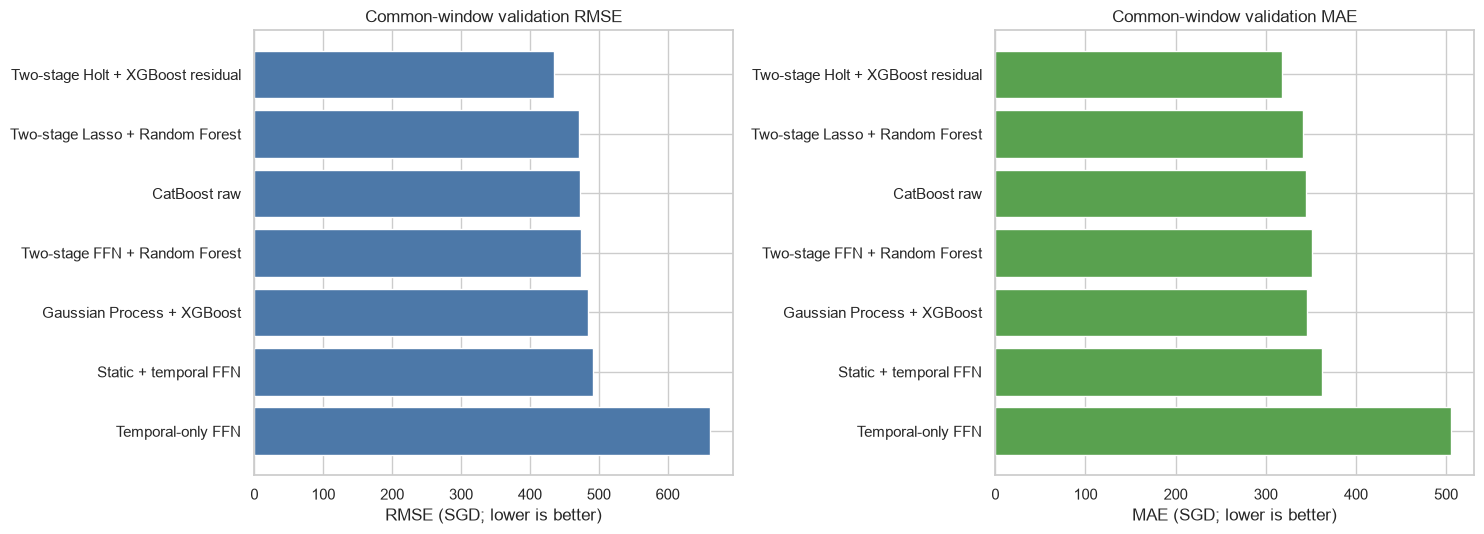

Saved: C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs\validation_metric_comparison.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_data = comparison.sort_values("validation_RMSE", ascending=False)

axes[0].barh(plot_data["display_name"], plot_data["validation_RMSE"], color="#4C78A8")
axes[0].set_title("Common-window validation RMSE")
axes[0].set_xlabel("RMSE (SGD; lower is better)")

axes[1].barh(plot_data["display_name"], plot_data["validation_MAE"], color="#59A14F")
axes[1].set_title("Common-window validation MAE")
axes[1].set_xlabel("MAE (SGD; lower is better)")

plt.tight_layout()
metric_plot_path = OUTPUT_ROOT / "validation_metric_comparison.png"
plt.savefig(metric_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {metric_plot_path}")


## 5. Row-level validation diagnostics

These plots use only models with complete row-level validation predictions.
Aggregate-only models remain in the headline table but cannot appear here.


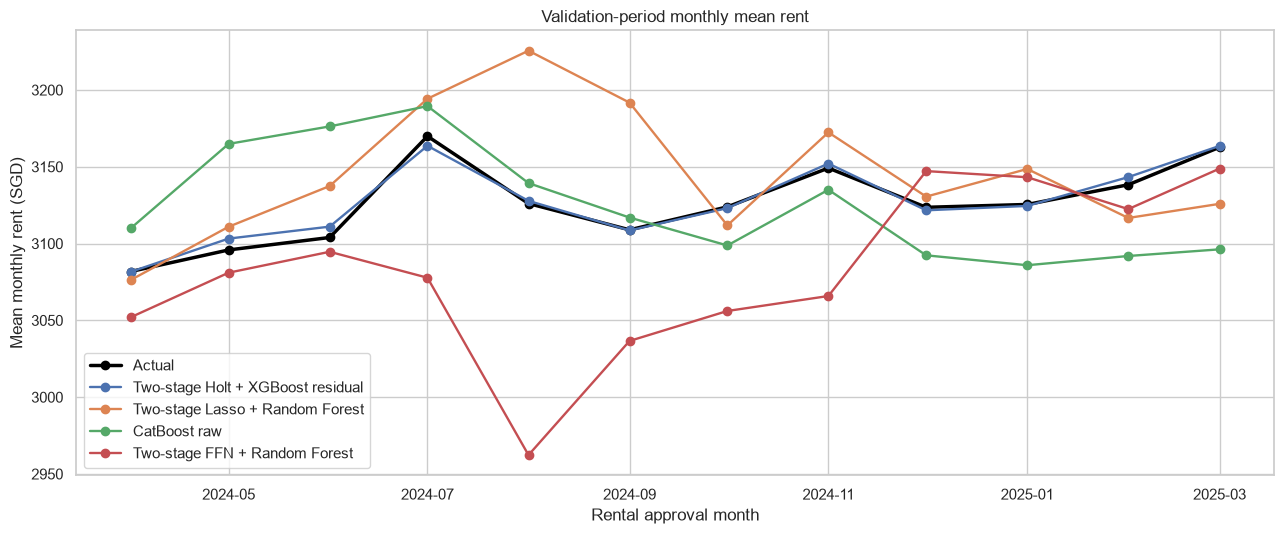

Saved: C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs\validation_monthly_predictions.png


In [9]:
ranked_row_models = [
    model for model in comparison.index
    if model in prediction_cache["validation"]
]
TOP_N = min(4, len(ranked_row_models))
top_row_models = ranked_row_models[:TOP_N]

if top_row_models:
    monthly_actual = (
        prediction_cache["validation"][top_row_models[0]]
        .groupby("RENT_APPROVAL_DATE")[TARGET]
        .mean()
    )
    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.plot(monthly_actual.index, monthly_actual.values, color="black", marker="o", linewidth=2.5, label="Actual")
    for model in top_row_models:
        monthly_prediction = (
            prediction_cache["validation"][model]
            .groupby("RENT_APPROVAL_DATE")["PREDICTION"]
            .mean()
        )
        ax.plot(monthly_prediction.index, monthly_prediction.values, marker="o", linewidth=1.7, label=MODEL_SPECS[model]["display"])
    ax.set_title("Validation-period monthly mean rent")
    ax.set_xlabel("Rental approval month")
    ax.set_ylabel("Mean monthly rent (SGD)")
    ax.legend()
    plt.tight_layout()
    path = OUTPUT_ROOT / "validation_monthly_predictions.png"
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")


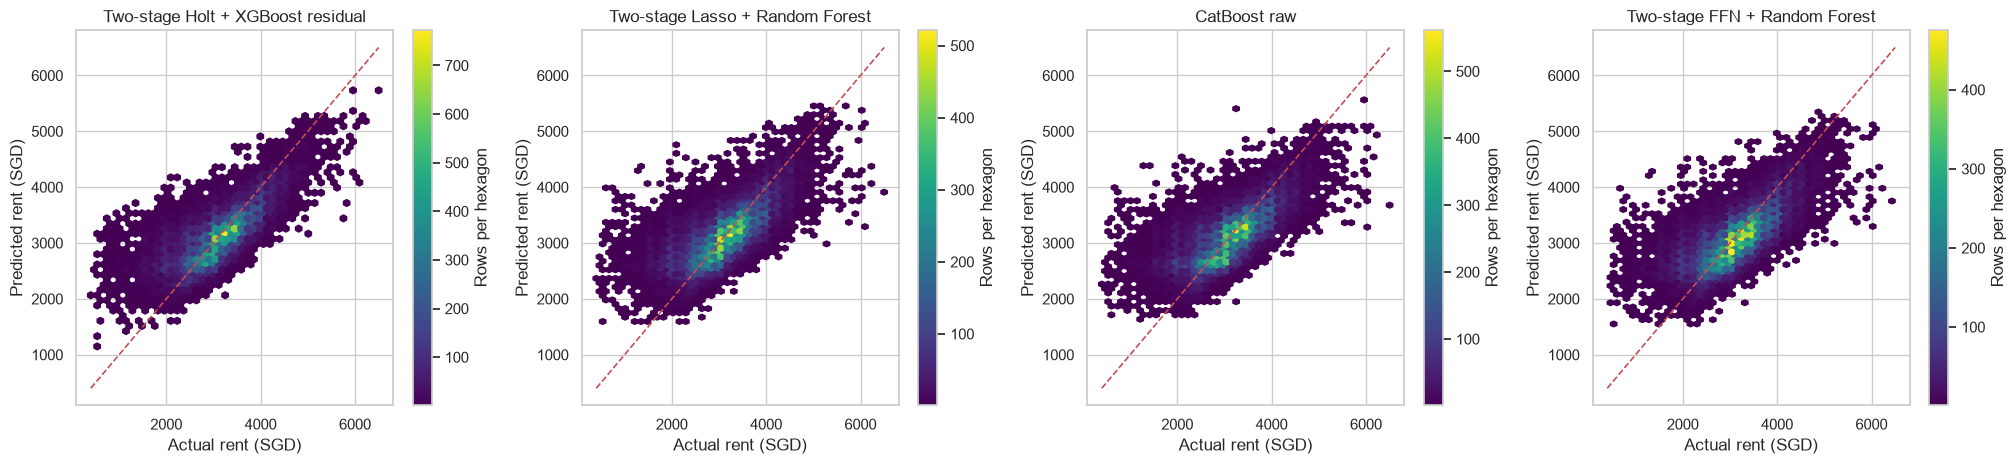

Saved: C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs\validation_actual_vs_predicted.png


In [10]:
if top_row_models:
    fig, axes = plt.subplots(1, TOP_N, figsize=(5.1 * TOP_N, 4.8), squeeze=False)
    for ax, model in zip(axes.ravel(), top_row_models):
        scored = prediction_cache["validation"][model]
        plot_min = min(scored[TARGET].min(), scored["PREDICTION"].min())
        plot_max = max(scored[TARGET].max(), scored["PREDICTION"].max())
        density = ax.hexbin(scored[TARGET], scored["PREDICTION"], gridsize=45, mincnt=1, cmap="viridis")
        ax.plot([plot_min, plot_max], [plot_min, plot_max], "r--", linewidth=1.2)
        ax.set_title(MODEL_SPECS[model]["display"])
        ax.set_xlabel("Actual rent (SGD)")
        ax.set_ylabel("Predicted rent (SGD)")
        fig.colorbar(density, ax=ax, label="Rows per hexagon")
    plt.tight_layout()
    path = OUTPUT_ROOT / "validation_actual_vs_predicted.png"
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")


display_name,CatBoost raw,Gaussian Process + XGBoost,Static + temporal FFN,Temporal-only FFN,Two-stage FFN + Random Forest,Two-stage Holt + XGBoost residual,Two-stage Lasso + Random Forest
flat_type,,,,,,,
1 room,379.0724,381.7628,521.7503,"1,454.3451",347.7139,317.7595,352.9017
2 room,441.1786,472.3001,457.3768,997.7358,437.5646,385.6336,439.8181
3 room,440.7882,469.0451,460.4053,616.1839,441.6055,417.0983,443.8982
4 room,477.9821,483.2143,497.3951,608.4148,476.8220,445.2462,474.2359
5 room,485.8492,490.1611,506.6756,711.6252,488.3210,439.5776,481.2186
executive,570.2716,573.9149,592.2338,832.1395,590.0978,471.3382,573.2568


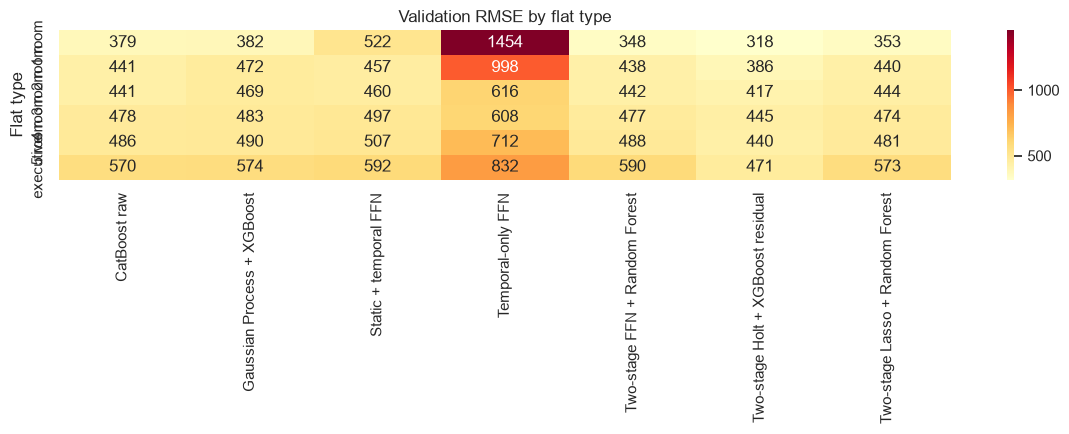

Saved: C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs\validation_rmse_by_flat_type.png


In [11]:
flat_type_rows = []
for model in ranked_row_models:
    scored = prediction_cache["validation"][model]
    for flat_type, group in scored.groupby("FLAT_TYPE"):
        flat_type_rows.append({
            "model": model,
            "display_name": MODEL_SPECS[model]["display"],
            "flat_type": flat_type,
            "rows": len(group),
            "RMSE": mean_squared_error(group[TARGET], group["PREDICTION"]) ** 0.5,
        })

flat_type_metrics = pd.DataFrame(flat_type_rows)
if not flat_type_metrics.empty:
    flat_type_metrics.to_csv(OUTPUT_ROOT / "validation_rmse_by_flat_type.csv", index=False)
    pivot = flat_type_metrics.pivot(index="flat_type", columns="display_name", values="RMSE")
    display(pivot)
    plt.figure(figsize=(12, max(4.5, 0.45 * len(pivot))))
    sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd")
    plt.title("Validation RMSE by flat type")
    plt.xlabel("")
    plt.ylabel("Flat type")
    plt.tight_layout()
    path = OUTPUT_ROOT / "validation_rmse_by_flat_type.png"
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")


## 6. Automated conclusion

The conclusion distinguishes a numerical winner from statistical certainty.
It also reports incomplete inputs so that missing predictions cannot be
mistaken for poor model performance.


In [12]:
best = comparison.iloc[0]
runner = comparison.iloc[1] if len(comparison) > 1 else None

print("CONCLUSION")
print("----------")
print(
    f"{best['display_name']} is the current validation winner: "
    f"RMSE = {best['validation_RMSE']:.2f}, MAE = {best['validation_MAE']:.2f}, "
    f"R² = {best['validation_R2']:.3f}, bias = {best['validation_BIAS']:.2f} SGD."
)
if runner is not None:
    difference = runner["validation_RMSE"] - best["validation_RMSE"]
    relative = difference / runner["validation_RMSE"] * 100
    print(
        f"It improves RMSE by {difference:.2f} SGD ({relative:.2f}%) over "
        f"the runner-up, {runner['display_name']}."
    )
    if relative < 1:
        print("The top-two gap is below 1%; treat them as practically close unless repeated temporal folds confirm the ordering.")

winner_train_coverage = best.get("train_coverage")
if pd.notna(winner_train_coverage) and winner_train_coverage < 0.999:
    print(
        f"Caveat: the supplied winner train predictions cover only {winner_train_coverage:.1%} "
        "of the common fit rows, so its train-validation gap is not directly comparable to full-window models."
    )

excluded = audit.loc[~audit["eligible_for_ranking"].astype(bool)]
if not excluded.empty:
    print("\nModels not ranked:")
    for _, row in excluded.iterrows():
        print(f"- {row['display_name']}: {row['validation_status']}")

print(
    "\nInterpretation: selection is based on the shared future validation window. "
    "The official Kaggle test must remain unused for tuning; its score is a final external check only."
)


CONCLUSION
----------
Two-stage Holt + XGBoost residual is the current validation winner: RMSE = 434.67, MAE = 318.36, R² = 0.565, bias = 1.18 SGD.
It improves RMSE by 36.05 SGD (7.66%) over the runner-up, Two-stage Lasso + Random Forest.
Caveat: the supplied winner train predictions cover only 67.2% of the common fit rows, so its train-validation gap is not directly comparable to full-window models.

Interpretation: selection is based on the shared future validation window. The official Kaggle test must remain unused for tuning; its score is a final external check only.


## 7. Audit final-refit predictions and create the Kaggle submission

Validation ranking and final prediction generation are intentionally separate.
The table below checks every available final-refit test file for 50,000 unique
identifiers, exact `0..49,999` alignment, finite predictions and confirmed
train + validation refitting. The Kaggle file is then created only for the
model selected on the common chronological validation window.


In [13]:
def resolve_final_test_file(model):
    override = FINAL_TEST_FILE_OVERRIDES.get(model)
    if override is not None:
        path = Path(override).expanduser()
        if path.is_file():
            return path.resolve(), model in CONFIRMED_FINAL_TEST_MODELS
        for root in BUNDLE_ROOTS:
            candidate = root / path
            if candidate.is_file():
                return candidate, model in CONFIRMED_FINAL_TEST_MODELS

    for relative in MODEL_SPECS[model].get("final_test", []):
        path = locate_file([relative])
        if path is not None:
            automatic_confirmation = Path(relative).name.startswith(("retrained_", "final_"))
            return path, automatic_confirmation or model in CONFIRMED_FINAL_TEST_MODELS

    if model == "catboost_raw":
        candidate = cfg.CATBOOST_OUTPUT_DIR / "submission_catboost.csv"
        metadata_path = candidate.parent / "model_metadata.json"
        if candidate.is_file() and metadata_path.is_file():
            metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
            confirmed = metadata.get("train_rows") == len(expected_train) + len(expected_val)
            return candidate, confirmed
    return None, False


expected_test_ids = official_test["ROW_ID"].to_numpy()
final_test_rows = []
resolved_final_tests = {}

for model, spec in MODEL_SPECS.items():
    path, refit_confirmed = resolve_final_test_file(model)
    record = {
        "model": model,
        "display_name": spec["display"],
        "test_file": str(path) if path is not None else None,
        "final_refit_confirmed": bool(refit_confirmed),
        "rows": np.nan,
        "identifier_match": False,
        "status": "not supplied",
    }
    valid_file = False
    if path is not None:
        try:
            prediction = load_predictions(path, spec.get("prediction_column"))
            identifier_match = np.array_equal(
                prediction["ROW_ID"].to_numpy(), expected_test_ids
            )
            record["rows"] = len(prediction)
            record["identifier_match"] = bool(identifier_match)
            if not identifier_match:
                record["status"] = "INVALID: identifiers do not exactly match 0..49,999"
            elif not refit_confirmed:
                record["status"] = "valid rows; final refit unconfirmed"
            else:
                record["status"] = "valid; final refit confirmed"
                valid_file = True
        except Exception as error:
            record["status"] = f"INVALID: {error}"
    resolved_final_tests[model] = {
        "path": path,
        "confirmed": bool(refit_confirmed),
        "valid": valid_file,
    }
    final_test_rows.append(record)

final_test_audit = pd.DataFrame(final_test_rows).set_index("model")
final_test_audit.to_csv(OUTPUT_ROOT / "final_test_prediction_audit.csv", index_label="model")
display(final_test_audit[[
    "display_name", "final_refit_confirmed", "rows", "identifier_match", "status"
]])

winner_final = resolved_final_tests[WINNER]
winner_test_path = winner_final["path"]
final_refit_confirmed = winner_final["confirmed"] and winner_final["valid"]
submission_path = OUTPUT_ROOT / "final_submission.csv"
metadata_path = OUTPUT_ROOT / "final_selection_metadata.json"
submission = None

if winner_test_path is None:
    print(f"Submission not created: no official-test prediction file was found for {winner_name}.")
elif not final_refit_confirmed:
    print(f"Submission not created: the final-test audit failed for {winner_name}.")
else:
    final_prediction = load_predictions(
        winner_test_path, MODEL_SPECS[WINNER].get("prediction_column")
    )
    submission = final_prediction.rename(
        columns={"ROW_ID": "Id", "PREDICTION": "Predicted"}
    )[["Id", "Predicted"]]
    submission.to_csv(submission_path, index=False)
    print(f"Created Kaggle submission: {submission_path}")
    display(submission.head())

selection_metadata = {
    "primary_metric": PRIMARY_METRIC,
    "winner": WINNER,
    "winner_display_name": winner_name,
    "validation_start": str(VALIDATION_START.date()),
    "validation_end": str(VALIDATION_END.date()),
    "validation_rows": int(len(expected_val)),
    "validation_RMSE": float(best["validation_RMSE"]),
    "validation_MAE": float(best["validation_MAE"]),
    "validation_R2": float(best["validation_R2"]),
    "test_prediction_file": str(winner_test_path) if winner_test_path else None,
    "final_refit_confirmed": bool(final_refit_confirmed),
    "submission_created": submission is not None,
}
metadata_path.write_text(json.dumps(selection_metadata, indent=2), encoding="utf-8")
print(f"Saved selection metadata: {metadata_path}")


,display_name,final_refit_confirmed,rows,identifier_match,status
model,,,,,
catboost_raw,CatBoost raw,True,50000,True,valid; final refit confirmed
static_temporal_ffn,Static + temporal FFN,True,50000,True,valid; final refit confirmed
temporal_ffn,Temporal-only FFN,True,50000,True,valid; final refit confirmed
two_stage_ffn_rf,Two-stage FFN + Random Forest,True,50000,True,valid; final refit confirmed
two_stage_lasso_rf,Two-stage Lasso + Random Forest,True,50000,True,valid; final refit confirmed
time_series_plus_residual,Two-stage Holt + XGBoost residual,True,50000,True,valid; final refit confirmed
gaussian_process_xgboost,Gaussian Process + XGBoost,True,50000,True,valid; final refit confirmed


Created Kaggle submission: C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs\final_submission.csv


,Id,Predicted
0,0,"3,008.2025"
1,1,"3,464.8469"
2,2,"3,161.8222"
3,3,"3,243.5876"
4,4,"3,437.0933"


Saved selection metadata: C:\Users\eliga\Downloads\Project_export\final_report\03_evaluation\overall_model_outputs\final_selection_metadata.json


## Reporting guidance

Use `model_comparison.csv` for the main report table and state that all seven
models were ranked on the same April 2024–March 2025 chronological validation
window. Report the winner's RMSE, MAE, R² and bias, plus the difference from
the runner-up.

The Gaussian Process + XGBoost model is now included using its corrected
35,158-row validation prediction file. Train metrics remain diagnostic rather
than a ranking criterion: a partial train window is clearly marked, CatBoost's
train score is its internal ordered-boosting metric, and gaps from unlike train
prediction protocols should not be compared literally.

Final-refit test files are audited only after the validation winner is chosen.
The Kaggle score remains an external check and must not be used to tune models
or retrospectively change the validation-based selection rule.
